# PN ResUNet v4.9.1 — GPU-safe paired five-channel experiment

This is a versioned runtime fix for v4.9. Scientific settings are unchanged.
The NumPy training arrays remain on CPU and `tf.data` transfers only individual
batches to the accelerator. This avoids TensorFlow Metal attempting to create
one GPU `_EagerConst` containing the full dataset.


# PN Detection Residual U-Net — v4.0 architecture ablation

This notebook is a controlled architecture experiment based on the v3.0 training workflow.
It uses the v6.0 synthetic dataset and keeps the loss, optimizer, normalization, data split
logic, `val_loss` checkpointing, detection metrics, and threshold-selection workflow unchanged.

**Only the network blocks are changed:** each plain two-convolution U-Net block is replaced by
a residual block with an identity shortcut when channel dimensions match and a 1×1 projection
shortcut when they do not. The encoder/decoder depth and feature widths remain
`32 → 64 → 128 → 256`.


In [1]:
import os
SEED=42
os.environ["PYTHONHASHSEED"]=str(SEED)
os.environ["TF_DETERMINISTIC_OPS"]="1"

from pathlib import Path
import json
import hashlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import GroupShuffleSplit
from scipy.ndimage import maximum_filter

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("TensorFlow version:",tf.__version__)

I0000 00:00:1791990606.003452 1985843 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791990606.051210 1985843 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791990607.188621 1985843 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


In [2]:
DATA_PATH=Path("all_PN_20000_grouped_5channel_snr_gated_v6.7.npz")
RUN_ID="v4.9.1_5channel_snr_gated_cpuinput"
MODEL_PATH=Path(f"best_PN_ResUNet_focal_all_grouped_{RUN_ID}.keras")
NORM_PATH=Path(f"PN_ResUNet_normalization_{RUN_ID}.npz")
SPLIT_PATH=Path(f"PN_ResUNet_split_manifest_{RUN_ID}.npz")
CONFIG_PATH=Path(f"PN_ResUNet_training_config_{RUN_ID}.json")

FLUX_SCALE=1e18
ASINH_PERCENTILE=90.0
ERROR_ASINH_PERCENTILE=90.0
BATCH_SIZE=32
LEARNING_RATE=3e-4
WEIGHT_DECAY=1e-5
CLIPNORM=1.0
MAX_EPOCHS=100

PEAK_THRESHOLD=0.30
MIN_DISTANCE=3
MATCH_TOLERANCE=1.0

COMPACT_NEGATIVE_TYPES=["compact_nonpn","compact_non-pn","nonpn_compact","hard_negative"]
BACKGROUND_TYPES=["background","empty","blank"]
DIFFUSE_NEGATIVE_TYPES=["diffuse_nonpn","diffuse_non-pn"]


## Load dataset

In [3]:
data=np.load(DATA_PATH,allow_pickle=True)
X=data["X"].astype(np.float32)
Y=data["Y"].astype(np.float32)
loss_masks=data["loss_masks"].astype(np.float32)
line_names=data["line_names"]
metadata=json.loads(data["metadata_json"].item())

group_key=next((k for k in ("group_ids","parent_ids","split_group_ids") if k in data.files),None)
type_key=next((k for k in ("sample_types","sample_type","source_types") if k in data.files),None)

if group_key is None:
    raise KeyError("Dataset is missing leakage-safe group IDs.")
if type_key is None:
    raise KeyError("Dataset is missing sample_types.")

group_ids=np.asarray(data[group_key]).astype(str)
sample_types=np.char.lower(np.asarray(data[type_key]).astype(str))

if len(group_ids)!=len(X) or len(sample_types)!=len(X):
    raise ValueError("group_ids and sample_types must have length N.")

print("Original X shape:",X.shape)
print("Original Y shape:",Y.shape)
print("Original loss-mask shape:",loss_masks.shape)
print("Lines:",line_names)
print("Unique groups:",len(np.unique(group_ids)))
print("Sample types:")
for name,count in zip(*np.unique(sample_types,return_counts=True)):
    print(f"  {name}: {count}")

Original X shape: (20000, 5, 64, 64)
Original Y shape: (20000, 1, 64, 64)
Original loss-mask shape: (20000, 1, 64, 64)
Lines: ['Hbeta' 'OIII5007' 'Halpha' 'NII6584' 'OIII5007_ERROR']
Unique groups: 139
Sample types:
  background: 194
  compact_nonpn: 7717
  diffuse_nonpn: 173
  pn_ignored_only: 636
  pn_positive: 11280


In [4]:
X=np.transpose(X,(0,2,3,1))
Y=np.transpose(Y,(0,2,3,1))
loss_masks=np.transpose(loss_masks,(0,2,3,1))

assert X.ndim==4 and X.shape[-1]==5
assert Y.ndim==4 and Y.shape[-1]==1
assert loss_masks.shape==Y.shape
assert X.shape[1:3]==(64,64) and Y.shape[1:3]==(64,64)
assert np.all((loss_masks==0.0)|(loss_masks==1.0))
print("Transposed X shape:",X.shape)
print("Transposed Y shape:",Y.shape)
print("Masked pixel fraction:",1.0-loss_masks.mean())


Transposed X shape: (20000, 64, 64, 5)
Transposed Y shape: (20000, 64, 64, 1)
Masked pixel fraction: 0.0011107326


## Recover unstandardized inputs if needed

In [5]:
if not np.all(np.isfinite(X)):
    raise ValueError("X contains NaN or Inf values.")
if not np.all(np.isfinite(Y)):
    raise ValueError("Y contains NaN or Inf values.")
if not np.all(np.isfinite(loss_masks)):
    raise ValueError("loss_masks contains NaN or Inf values.")


## Inspect one sample

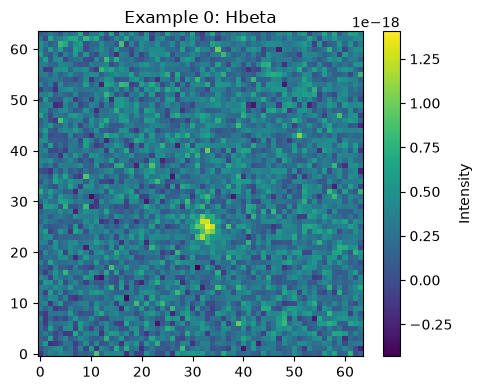

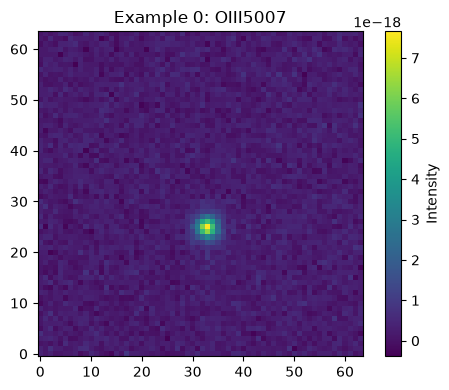

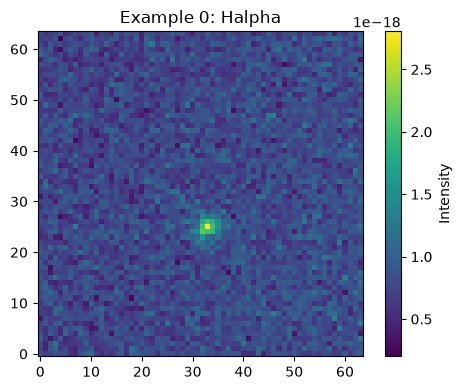

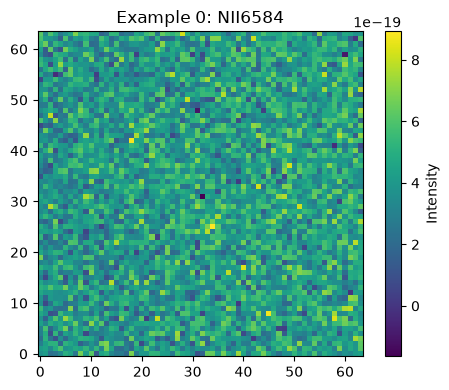

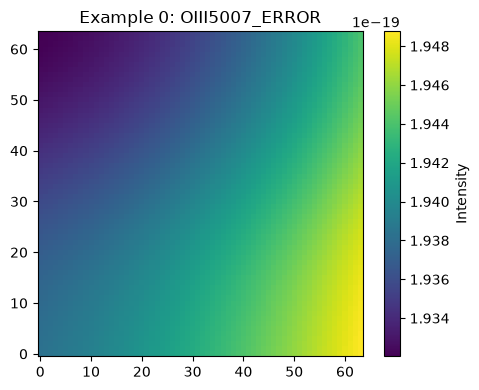

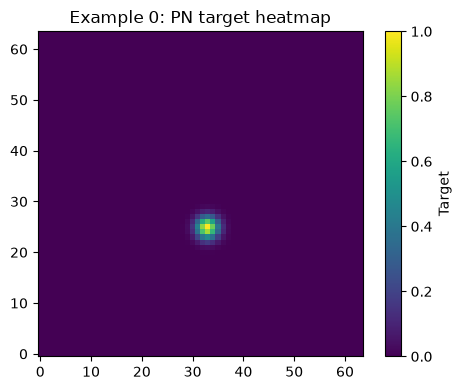

In [6]:
i=0
for c,name in enumerate(line_names):
    plt.figure(figsize=(5,4))
    plt.imshow(X[i,:,:,c],origin="lower")
    plt.colorbar(label="Intensity")
    plt.title(f"Example {i}: {name}")
    plt.tight_layout()
    plt.show()

plt.figure(figsize=(5,4))
plt.imshow(Y[i,:,:,0],origin="lower")
plt.colorbar(label="Target")
plt.title(f"Example {i}: PN target heatmap")
plt.tight_layout()
plt.show()

## Leakage-safe train / validation / test split

In [7]:
has_pn=np.any(Y>=0.999,axis=(1,2,3)).astype(np.int32)
injected_pn_counts=np.asarray([m.get("n_pn",0) for m in metadata],dtype=np.int32)
ignored_pn_counts=np.asarray([m.get("n_pn_ignored",0) for m in metadata],dtype=np.int32)
has_injected_pn=injected_pn_counts>0
has_ignored_pn=ignored_pn_counts>0

def best_group_holdout(indices,groups,labels,holdout_fraction,seed,n_trials=200):
    indices=np.asarray(indices)
    groups=np.asarray(groups)
    labels=np.asarray(labels)
    if len(np.unique(groups[indices]))<2:
        raise ValueError("Not enough independent groups for leakage-safe splitting.")
    overall_pos=labels[indices].mean()
    target_n=holdout_fraction*len(indices)
    best=None
    for t in range(n_trials):
        splitter=GroupShuffleSplit(n_splits=1,test_size=holdout_fraction,random_state=seed+t)
        keep_local,hold_local=next(splitter.split(np.zeros(len(indices)),labels[indices],groups=groups[indices]))
        keep_idx=indices[keep_local]
        hold_idx=indices[hold_local]
        hold_error=abs(len(hold_idx)-target_n)/max(len(indices),1)
        balance_error=abs(labels[keep_idx].mean()-overall_pos)+abs(labels[hold_idx].mean()-overall_pos)
        score=hold_error+balance_error
        if best is None or score<best[0]:
            best=(score,keep_idx,hold_idx)
    return best[1],best[2]

all_idx=np.arange(len(X))
train_idx,temp_idx=best_group_holdout(all_idx,group_ids,has_pn,0.20,SEED)
val_idx,test_idx=best_group_holdout(temp_idx,group_ids,has_pn,0.50,SEED+1000)

train_groups=set(group_ids[train_idx])
val_groups=set(group_ids[val_idx])
test_groups=set(group_ids[test_idx])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

types_train=sample_types[train_idx]
types_val=sample_types[val_idx]
types_test=sample_types[test_idx]

def split_report(name,idx,types):
    compact=np.isin(types,COMPACT_NEGATIVE_TYPES)
    background=np.isin(types,BACKGROUND_TYPES)
    print(f"{name:5s}: N={len(idx):5d} | groups={len(np.unique(group_ids[idx])):4d} | positive-PN={has_pn[idx].mean():.3f} | ignored-PN={has_ignored_pn[idx].mean():.3f} | compact non-PN={compact.sum():4d} | background={background.sum():4d}")

print("Leakage-safe split:")
split_report("Train",train_idx,types_train)
split_report("Val",val_idx,types_val)
split_report("Test",test_idx,types_test)

negative_train=~has_injected_pn[train_idx]
compact_negative_train=negative_train&np.isin(types_train,COMPACT_NEGATIVE_TYPES)

if negative_train.sum()==0:
    raise ValueError("Training set contains no negative samples.")

compact_fraction=compact_negative_train.sum()/negative_train.sum()
print(f"Fraction of training negatives that are compact non-PNe: {compact_fraction:.3f}")

if compact_fraction<0.5:
    print("WARNING: realistic compact non-PNe do not dominate the negative training set.")

Leakage-safe split:
Train: N=16003 | groups= 111 | positive-PN=0.564 | ignored-PN=0.056 | compact non-PN=6155 | background= 157
Val  : N= 2002 | groups=  14 | positive-PN=0.564 | ignored-PN=0.056 | compact non-PN= 788 | background=  23
Test : N= 1995 | groups=  14 | positive-PN=0.562 | ignored-PN=0.059 | compact non-PN= 774 | background=  14
Fraction of training negatives that are compact non-PNe: 0.954


## Robust asinh preprocessing + train-only standardization

In [8]:
# Train-only normalization. Flux behavior is identical to v4.7; the
# positive-valued error channel has its own stable asinh scale and z-score.
flux_X=X[...,:4]
error_X=X[...,4:5]
if np.any(~np.isfinite(error_X)) or np.any(error_X<=0):
    raise ValueError("The OIII error channel must be finite and strictly positive.")

def calculate_flux_asinh_scale(x,indices,percentile):
    values=np.abs(x[indices].astype(np.float32)*np.float32(FLUX_SCALE))
    scales=np.percentile(values,percentile,axis=(0,1,2))
    if np.any(~np.isfinite(scales)) or np.any(scales<=0):
        raise ValueError(f"Invalid flux asinh scales: {scales}")
    return scales

asinh_scale=calculate_flux_asinh_scale(flux_X,train_idx,ASINH_PERCENTILE)
asinh_scale32=asinh_scale.astype(np.float32)
error_asinh_scale=float(np.percentile(error_X[train_idx],ERROR_ASINH_PERCENTILE))
if not np.isfinite(error_asinh_scale) or error_asinh_scale<=0:
    raise ValueError(f"Invalid error asinh scale: {error_asinh_scale}")

flux_train_t=np.arcsinh(
    flux_X[train_idx].astype(np.float32)*np.float32(FLUX_SCALE)/asinh_scale32
)
error_train_t=np.arcsinh(
    error_X[train_idx].astype(np.float32)/np.float32(error_asinh_scale)
)
flux_means=flux_train_t.mean(axis=(0,1,2),dtype=np.float64)
flux_stds=flux_train_t.std(axis=(0,1,2),dtype=np.float64)
error_mean=float(error_train_t.mean(dtype=np.float64))
error_std=float(error_train_t.std(dtype=np.float64))
if np.any(~np.isfinite(flux_means)) or np.any(~np.isfinite(flux_stds)) or np.any(flux_stds<=0):
    raise ValueError("Invalid flux normalization moments.")
if not np.isfinite(error_mean) or not np.isfinite(error_std) or error_std<=0:
    raise ValueError("Invalid error normalization moments.")

def preprocess(x):
    x=np.asarray(x,dtype=np.float32)
    flux_t=np.arcsinh(x[...,:4]*np.float32(FLUX_SCALE)/asinh_scale32)
    flux_z=(flux_t-flux_means.astype(np.float32))/flux_stds.astype(np.float32)
    error_t=np.arcsinh(x[...,4:5]/np.float32(error_asinh_scale))
    error_z=(error_t-np.float32(error_mean))/np.float32(error_std)
    return np.concatenate([flux_z,error_z],axis=-1).astype(np.float32)

X_train=preprocess(X[train_idx])
X_val=preprocess(X[val_idx])
X_test=preprocess(X[test_idx])
Y_train=Y[train_idx].astype(np.float32)
Y_val=Y[val_idx].astype(np.float32)
Y_test=Y[test_idx].astype(np.float32)
M_train=loss_masks[train_idx].astype(np.float32)
M_val=loss_masks[val_idx].astype(np.float32)
M_test=loss_masks[test_idx].astype(np.float32)
Y_train_packed=np.concatenate([Y_train,M_train],axis=-1)
Y_val_packed=np.concatenate([Y_val,M_val],axis=-1)
Y_test_packed=np.concatenate([Y_test,M_test],axis=-1)

channel_means=np.concatenate([flux_means,[error_mean]])
channel_stds=np.concatenate([flux_stds,[error_std]])
print("Flux asinh scales:",asinh_scale)
print("OIII-error asinh scale:",error_asinh_scale)
print("Train-only transformed means:",channel_means)
print("Train-only transformed stds:",channel_stds)
print("Normalized train means:",X_train.mean(axis=(0,1,2),dtype=np.float64))
print("Normalized train stds:",X_train.std(axis=(0,1,2),dtype=np.float64))


Flux asinh scales: [ 4.457706   2.5258625 19.194212   7.3572855]
OIII-error asinh scale: 3.2379548223627264e-19
Train-only transformed means: [0.48417569 0.45935423 0.46532187 0.47282608 0.69988282]
Train-only transformed stds: [0.87945757 0.63003221 0.8945078  0.80592779 0.11881746]
Normalized train means: [ 1.13664889e-08  1.75785391e-08  4.33796436e-09 -1.58553475e-08
  1.55345371e-07]
Normalized train stds: [0.99999997 0.99999996 0.99999997 0.99999999 0.99999998]


In [9]:
np.savez(
    SPLIT_PATH,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    train_groups=np.asarray(sorted(train_groups)),
    val_groups=np.asarray(sorted(val_groups)),
    test_groups=np.asarray(sorted(test_groups))
)
print("Saved split manifest:",SPLIT_PATH)

Saved split manifest: PN_ResUNet_split_manifest_v4.9.1_5channel_snr_gated_cpuinput.npz


## Deterministic augmentation and tf.data pipelines

In [10]:
def augment(index,x,y):
    index=tf.cast(index,tf.int32)
    seed=tf.stack([tf.cast(SEED,tf.int32),index])
    seeds=tf.random.experimental.stateless_split(seed,3)
    k=tf.random.stateless_uniform([],seed=seeds[0],minval=0,maxval=4,dtype=tf.int32)
    x=tf.image.rot90(x,k); y=tf.image.rot90(y,k)
    do_lr=tf.random.stateless_uniform([],seed=seeds[1])>0.5
    x=tf.cond(do_lr,lambda:tf.image.flip_left_right(x),lambda:x)
    y=tf.cond(do_lr,lambda:tf.image.flip_left_right(y),lambda:y)
    do_ud=tf.random.stateless_uniform([],seed=seeds[2])>0.5
    x=tf.cond(do_ud,lambda:tf.image.flip_up_down(x),lambda:x)
    y=tf.cond(do_ud,lambda:tf.image.flip_up_down(y),lambda:y)
    return x,y


options=tf.data.Options()
options.experimental_deterministic=True

# Critical TensorFlow-Metal fix: create the backing tensors and every tf.data
# pipeline on CPU. Keras still executes the model on the selected accelerator
# and copies only one BATCH_SIZE batch at a time.
with tf.device("/CPU:0"):
    train_ds=(
        tf.data.Dataset.from_tensor_slices((X_train,Y_train_packed))
        .shuffle(len(X_train),seed=SEED,reshuffle_each_iteration=True)
        .enumerate()
        .map(
            lambda idx,data:augment(idx,data[0],data[1]),
            num_parallel_calls=tf.data.AUTOTUNE,
            deterministic=True,
        )
        .batch(BATCH_SIZE)
        .prefetch(2)
        .with_options(options)
    )
    val_ds=(
        tf.data.Dataset.from_tensor_slices((X_val,Y_val_packed))
        .batch(BATCH_SIZE)
        .prefetch(2)
        .with_options(options)
    )
    test_ds=(
        tf.data.Dataset.from_tensor_slices((X_test,Y_test_packed))
        .batch(BATCH_SIZE)
        .prefetch(2)
        .with_options(options)
    )

sample_x,sample_y=next(iter(train_ds.take(1)))
print("First batch devices:",sample_x.device,sample_y.device)
print("First batch shapes:",sample_x.shape,sample_y.shape)


I0000 00:00:1791990640.263549 1985843 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1082 MB memory:  -> device: 0, name: NVIDIA RTX A5000, pci bus id: 0000:b1:00.0, compute capability: 8.6
I0000 00:00:1791990640.264925 1985843 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 22159 MB memory:  -> device: 1, name: NVIDIA RTX A5000, pci bus id: 0000:ca:00.0, compute capability: 8.6


First batch devices: /job:localhost/replica:0/task:0/device:CPU:0 /job:localhost/replica:0/task:0/device:CPU:0
First batch shapes: (32, 64, 64, 5) (32, 64, 64, 2)


## U-Net model

In [11]:
def residual_block(x, filters, name=None):
    """Two 3x3 convolutions with a residual shortcut.

    The shortcut is identity when x already has `filters` channels; otherwise a
    1x1 projection + BatchNorm is used so the tensors can be added.
    """
    shortcut = x

    y = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_initializer="he_normal",
        name=None if name is None else f"{name}_conv1",
    )(x)
    y = layers.BatchNormalization(
        name=None if name is None else f"{name}_bn1"
    )(y)
    y = layers.ReLU(
        name=None if name is None else f"{name}_relu1"
    )(y)

    y = layers.Conv2D(
        filters, 3, padding="same", use_bias=False,
        kernel_initializer="he_normal",
        name=None if name is None else f"{name}_conv2",
    )(y)
    y = layers.BatchNormalization(
        name=None if name is None else f"{name}_bn2"
    )(y)

    if x.shape[-1] != filters:
        shortcut = layers.Conv2D(
            filters, 1, padding="same", use_bias=False,
            kernel_initializer="he_normal",
            name=None if name is None else f"{name}_proj",
        )(shortcut)
        shortcut = layers.BatchNormalization(
            name=None if name is None else f"{name}_proj_bn"
        )(shortcut)

    y = layers.Add(
        name=None if name is None else f"{name}_add"
    )([y, shortcut])
    y = layers.ReLU(
        name=None if name is None else f"{name}_out"
    )(y)
    return y


def build_unet(input_shape=(64, 64, 5)):
    inputs = keras.Input(shape=input_shape)

    # Encoder
    c1 = residual_block(inputs, 32, name="enc1")
    p1 = layers.MaxPooling2D((2, 2))(c1)

    c2 = residual_block(p1, 64, name="enc2")
    p2 = layers.MaxPooling2D((2, 2))(c2)

    c3 = residual_block(p2, 128, name="enc3a")
    c3 = residual_block(c3, 128, name="enc3b")
    p3 = layers.MaxPooling2D((2, 2))(c3)

    # Deeper bottleneck
    b = residual_block(p3, 256, name="bottleneck1")
    b = residual_block(b, 256, name="bottleneck2")
    b = layers.Dropout(0.20)(b)

    # Decoder
    u3 = layers.Conv2DTranspose(
        128, 2, strides=2, padding="same"
    )(b)
    u3 = layers.Concatenate()([u3, c3])

    c4 = residual_block(u3, 128, name="dec3a")
    c4 = residual_block(c4, 128, name="dec3b")

    u2 = layers.Conv2DTranspose(
        64, 2, strides=2, padding="same"
    )(c4)
    u2 = layers.Concatenate()([u2, c2])
    c5 = residual_block(u2, 64, name="dec2")

    u1 = layers.Conv2DTranspose(
        32, 2, strides=2, padding="same"
    )(c5)
    u1 = layers.Concatenate()([u1, c1])
    c6 = residual_block(u1, 32, name="dec1")

    outputs = layers.Conv2D(
        1, 1, activation="sigmoid",
        name="pn_heatmap"
    )(c6)

    return keras.Model(inputs, outputs, name="PN_ResUNet")


## Focal loss

In [12]:
@tf.keras.utils.register_keras_serializable()
def center_focal_loss(y_true_and_mask,y_pred):
    target=y_true_and_mask[...,:1]
    loss_mask=y_true_and_mask[...,1:2]
    eps=1e-6
    y_pred=tf.clip_by_value(y_pred,eps,1.0-eps)
    positive=tf.cast(target>=0.999,tf.float32)
    negative=tf.cast(target<0.999,tf.float32)
    negative_weights=tf.pow(1.0-target,4.0)
    positive_loss=-tf.math.log(y_pred)*tf.pow(1.0-y_pred,2.0)*positive
    negative_loss=-tf.math.log(1.0-y_pred)*tf.pow(y_pred,2.0)*negative_weights*negative
    positive_loss*=loss_mask
    negative_loss*=loss_mask
    num_positive=tf.reduce_sum(positive*loss_mask)
    total_loss=tf.reduce_sum(positive_loss)+tf.reduce_sum(negative_loss)
    return total_loss/tf.maximum(num_positive,1.0)


## Source-level detection metrics

In [13]:
def find_pn_centers(heatmap,threshold=0.30,min_distance=3):
    size=2*min_distance+1
    local_max=heatmap==maximum_filter(heatmap,size=size,mode="constant")
    detected=local_max&(heatmap>=threshold)
    y,x=np.where(detected)
    scores=heatmap[y,x]
    order=np.argsort(scores)[::-1]
    return np.column_stack([x[order],y[order],scores[order]])

def find_true_centers(target,threshold=0.999,min_distance=1):
    size=2*min_distance+1
    local_max=target==maximum_filter(target,size=size,mode="constant")
    detected=local_max&(target>=threshold)
    y,x=np.where(detected)
    return np.column_stack([x,y]).astype(np.float32)

def match_detections(predicted,true_centers,tolerance=1.0):
    if len(predicted)==0:
        return 0,0,len(true_centers),[]
    if len(true_centers)==0:
        return 0,len(predicted),0,[]
    pred_xy=np.asarray(predicted[:,:2],dtype=np.float32)
    true_xy=np.asarray(true_centers,dtype=np.float32)
    used_true=set()
    tp=0
    localization_errors=[]
    for px,py in pred_xy:
        distances=np.sqrt((true_xy[:,0]-px)**2+(true_xy[:,1]-py)**2)
        for j in np.argsort(distances):
            if distances[j]>tolerance:
                break
            if j not in used_true:
                used_true.add(j)
                tp+=1
                localization_errors.append(float(distances[j]))
                break
    fp=len(pred_xy)-tp
    fn=len(true_xy)-tp
    return tp,fp,fn,localization_errors

def evaluate_detector(model,X_eval,Y_eval,loss_masks=None,threshold=0.30,min_distance=3,match_tolerance=1.0,verbose=0):
    predictions=model.predict(X_eval,batch_size=BATCH_SIZE,verbose=verbose)
    total_tp=total_fp=total_fn=0
    total_tn=total_negative_images=total_negative_images_with_fp=0
    all_errors=[]
    if loss_masks is None:
        loss_masks=np.ones_like(Y_eval,dtype=np.float32)
    for pred_map,true_map,valid_mask in zip(predictions,Y_eval,loss_masks):
        pred_centers=find_pn_centers(pred_map[:,:,0],threshold,min_distance)
        if len(pred_centers):
            px=np.clip(np.rint(pred_centers[:,0]).astype(int),0,valid_mask.shape[1]-1)
            py=np.clip(np.rint(pred_centers[:,1]).astype(int),0,valid_mask.shape[0]-1)
            pred_centers=pred_centers[valid_mask[py,px,0]>0.5]
        true_centers=find_true_centers(true_map[:,:,0])
        if len(true_centers)==0:
            total_negative_images+=1
            if len(pred_centers)==0:
                total_tn+=1
            else:
                total_negative_images_with_fp+=1
        tp,fp,fn,errors=match_detections(pred_centers,true_centers,match_tolerance)
        total_tp+=tp
        total_fp+=fp
        total_fn+=fn
        all_errors.extend(errors)
    precision=total_tp/(total_tp+total_fp) if total_tp+total_fp else 0.0
    recall=total_tp/(total_tp+total_fn) if total_tp+total_fn else 0.0
    f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
    specificity=total_tn/total_negative_images if total_negative_images else np.nan
    fp_image_rate=total_negative_images_with_fp/total_negative_images if total_negative_images else np.nan
    errors=np.asarray(all_errors,dtype=np.float32)
    return {
        "TP":total_tp,
        "FP":total_fp,
        "FN":total_fn,
        "TN":total_tn,
        "negative_images":total_negative_images,
        "negative_images_with_FP":total_negative_images_with_fp,
        "specificity":specificity,
        "false_positive_image_rate":fp_image_rate,
        "precision":precision,
        "recall":recall,
        "f1":f1,
        "mean_localization_error":float(np.mean(errors)) if len(errors) else np.nan,
        "median_localization_error":float(np.median(errors)) if len(errors) else np.nan,
        "rmse_localization_error":float(np.sqrt(np.mean(errors**2))) if len(errors) else np.nan,
        "std_localization_error":float(np.std(errors)) if len(errors) else np.nan,
        "localization_errors":errors
    }

def negative_subset_fp_rate(model,X_subset,Y_subset,type_subset,has_injected_pn_subset,threshold):
    pred_all=model.predict(X_subset,batch_size=BATCH_SIZE,verbose=0)
    rows=[]
    for target_type,aliases in {
        "all_pn_free":np.unique(type_subset),
        "compact_nonpn":COMPACT_NEGATIVE_TYPES,
        "diffuse_nonpn":DIFFUSE_NEGATIVE_TYPES,
        "background":BACKGROUND_TYPES,
    }.items():
        mask=np.isin(type_subset,aliases)
        mask&=~has_injected_pn_subset
        n=int(mask.sum())
        if n==0:
            rows.append((target_type,0,np.nan))
            continue
        with_fp=0
        for pred_map in pred_all[mask]:
            detections=find_pn_centers(pred_map[:,:,0],threshold,MIN_DISTANCE)
            with_fp+=int(len(detections)>0)
        rows.append((target_type,n,with_fp/n))
    print("negative_type     N     image_FP_rate")
    for name,n,rate in rows:
        print(f"{name:15s} {n:5d}   {rate:.3f}" if np.isfinite(rate) else f"{name:15s} {n:5d}   nan")

## Build and compile

In [14]:
keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model=build_unet()

optimizer=keras.optimizers.AdamW(
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    clipnorm=CLIPNORM
)

model.compile(optimizer=optimizer,loss=center_focal_loss)
model.summary()

with open(f"model_summary_resunet_{RUN_ID}.txt","w") as f:
    model.summary(print_fn=lambda line:f.write(line+"\n"))

Model: "PN_ResUNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 5) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv1 (Conv2D) │ (None, 64, 64,    │      1,440 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_bn1            │ (None, 64, 64,    │        128 │ enc1_conv1[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_relu1 (ReLU)   │ (None, 64, 64,    │          0 │ enc1_bn1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv2 (Conv2D) │ (None, 64, 64,    │      9,216 │ enc1_relu1[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_proj (Conv2D)  │ (None, 64, 64,    │        160 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_bn2            │ (None, 64, 64,    │        128 │ enc1_conv2[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_proj_bn        │ (None, 64, 64,    │        128 │ enc1_proj[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_add (Add)      │ (None, 64, 64,    │          0 │ enc1_bn2[0][0],   │
│                     │ 32)               │            │ enc1_proj_bn[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_out (ReLU)     │ (None, 64, 64,    │          0 │ enc1_add[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 32, 32,    │          0 │ enc1_out[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv1 (Conv2D) │ (None, 32, 32,    │     18,432 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_bn1            │ (None, 32, 32,    │        256 │ enc2_conv1[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_relu1 (ReLU)   │ (None, 32, 32,    │          0 │ enc2_bn1[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv2 (Conv2D) │ (None, 32, 32,    │     36,864 │ enc2_relu1[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_proj (Conv2D)  │ (None, 32, 32,    │      2,048 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_bn2            │ (None, 32, 32,    │        256 │ enc2_conv2[0][0]

 Total params: 3,792,961 (14.47 MB)

 Trainable params: 3,786,689 (14.45 MB)

 Non-trainable params: 6,272 (24.50 KB)

## Callbacks

In [15]:
class DetectionMetricsLogger(keras.callbacks.Callback):
    def __init__(self,X_val,Y_val,M_val,threshold,min_distance,match_tolerance):
        super().__init__()
        self.X_val=X_val
        self.Y_val=Y_val
        self.M_val=M_val
        self.threshold=threshold
        self.min_distance=min_distance
        self.match_tolerance=match_tolerance
        self.precision=[]
        self.recall=[]
        self.f1=[]

    def on_epoch_end(self,epoch,logs=None):
        m=evaluate_detector(
            self.model,self.X_val,self.Y_val,self.M_val,
            threshold=self.threshold,
            min_distance=self.min_distance,
            match_tolerance=self.match_tolerance,
            verbose=0
        )
        self.precision.append(m["precision"])
        self.recall.append(m["recall"])
        self.f1.append(m["f1"])
        if logs is not None:
            logs["val_source_precision"]=m["precision"]
            logs["val_source_recall"]=m["recall"]
            logs["val_source_f1"]=m["f1"]
        print(f" - val_source_precision: {m['precision']:.4f} - val_source_recall: {m['recall']:.4f} - val_source_f1: {m['f1']:.4f}")

class LearningRateLogger(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.values=[]

    def on_epoch_end(self,epoch,logs=None):
        lr=float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))
        self.values.append(lr)
        if logs is not None:
            logs["learning_rate_logged"]=lr

detection_logger=DetectionMetricsLogger(
    X_val,Y_val,M_val,
    threshold=PEAK_THRESHOLD,
    min_distance=MIN_DISTANCE,
    match_tolerance=MATCH_TOLERANCE
)

lr_logger=LearningRateLogger()

callbacks=[
    keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),
    detection_logger,
    lr_logger
]

## Train

In [16]:
history=model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=MAX_EPOCHS,
    callbacks=callbacks
)

Epoch 1/100


/home/gsafari/miniconda3/envs/tensorflow-gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
E0000 00:00:1791990653.938001 1985843 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/PN_ResUNet_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1791990655.364079 1986065 cuda_dnn.cc:461] Loaded cuDNN version 92600


501/501 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - loss: 22.7925
Epoch 1: val_loss improved from None to 0.67154, saving model to best_PN_ResUNet_focal_all_grouped_v4.9.1_5channel_snr_gated_cpuinput.keras

Epoch 1: finished saving model to best_PN_ResUNet_focal_all_grouped_v4.9.1_5channel_snr_gated_cpuinput.keras


E0000 00:00:1791990679.154316 1985843 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


 - val_source_precision: 0.7243 - val_source_recall: 0.7774 - val_source_f1: 0.7499
501/501 ━━━━━━━━━━━━━━━━━━━━ 36s 47ms/step - loss: 22.7925 - val_loss: 0.6715 - learning_rate: 3.0000e-04 - val_source_precision: 0.7243 - val_source_recall: 0.7774 - val_source_f1: 0.7499 - learning_rate_logged: 3.0000e-04
Epoch 2/100
501/501 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.5375
Epoch 2: val_loss improved from 0.67154 to 0.55071, saving model to best_PN_ResUNet_focal_all_grouped_v4.9.1_5channel_snr_gated_cpuinput.keras

Epoch 2: finished saving model to best_PN_ResUNet_focal_all_grouped_v4.9.1_5channel_snr_gated_cpuinput.keras


E0000 00:00:1791990701.854120 1985843 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


... (107 outputs left out)

E0000 00:00:1791991874.699962 1985843 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


 - val_source_precision: 0.7613 - val_source_recall: 0.9500 - val_source_f1: 0.8452
501/501 ━━━━━━━━━━━━━━━━━━━━ 22s 43ms/step - loss: 0.1601 - val_loss: 0.2586 - learning_rate: 3.7500e-05 - val_source_precision: 0.7613 - val_source_recall: 0.9500 - val_source_f1: 0.8452 - learning_rate_logged: 3.7500e-05
Epoch 57/100
501/501 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - loss: 0.1609
Epoch 57: val_loss did not improve from 0.24068


E0000 00:00:1791991896.256091 1985843 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


 - val_source_precision: 0.7609 - val_source_recall: 0.9568 - val_source_f1: 0.8477
501/501 ━━━━━━━━━━━━━━━━━━━━ 22s 43ms/step - loss: 0.1609 - val_loss: 0.2616 - learning_rate: 3.7500e-05 - val_source_precision: 0.7609 - val_source_recall: 0.9568 - val_source_f1: 0.8477 - learning_rate_logged: 3.7500e-05
Epoch 57: early stopping
Restoring model weights from the end of the best epoch: 45.


## Training curves

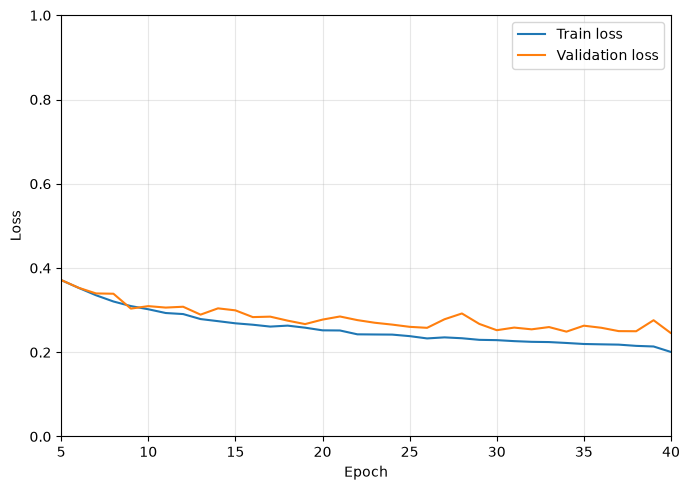

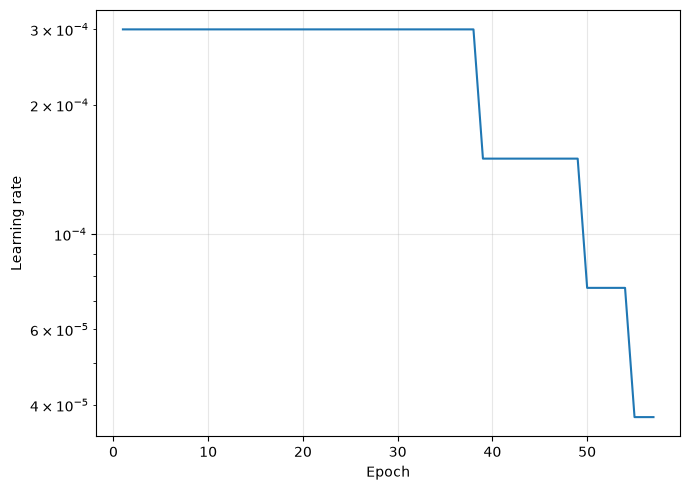

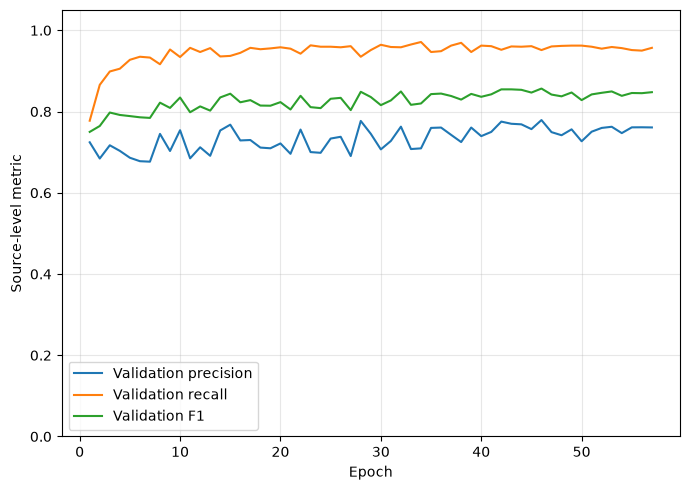

In [17]:
epochs=np.arange(1,len(history.history["loss"])+1)

plt.figure(figsize=(7,5))
plt.plot(epochs,history.history["loss"],label="Train loss")
plt.plot(epochs,history.history["val_loss"],label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.ylim(0,1)
plt.xlim(5, 40)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
plt.plot(np.arange(1,len(lr_logger.values)+1),lr_logger.values)
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

metric_epochs=np.arange(1,len(detection_logger.f1)+1)

plt.figure(figsize=(7,5))
plt.plot(metric_epochs,detection_logger.precision,label="Validation precision")
plt.plot(metric_epochs,detection_logger.recall,label="Validation recall")
plt.plot(metric_epochs,detection_logger.f1,label="Validation F1")
plt.xlabel("Epoch")
plt.ylabel("Source-level metric")
plt.ylim(0,1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Reload best model and inspect prediction

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.2416
Best-model test loss: 0.24160443246364594


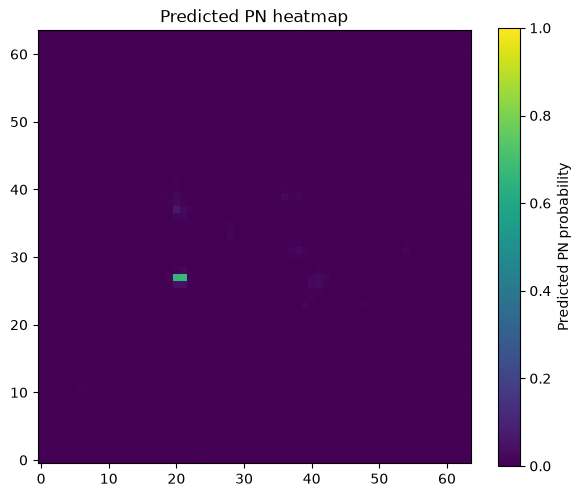

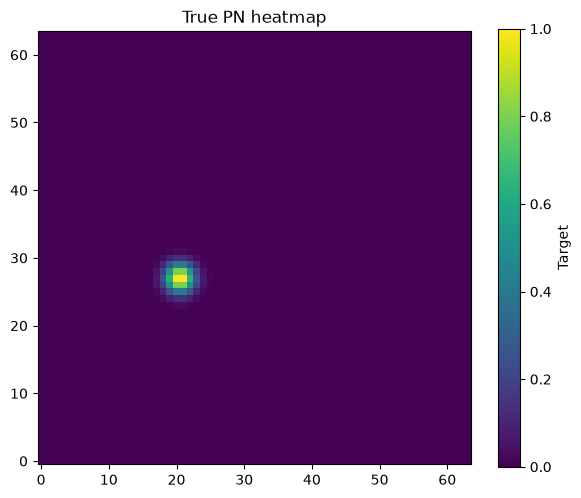

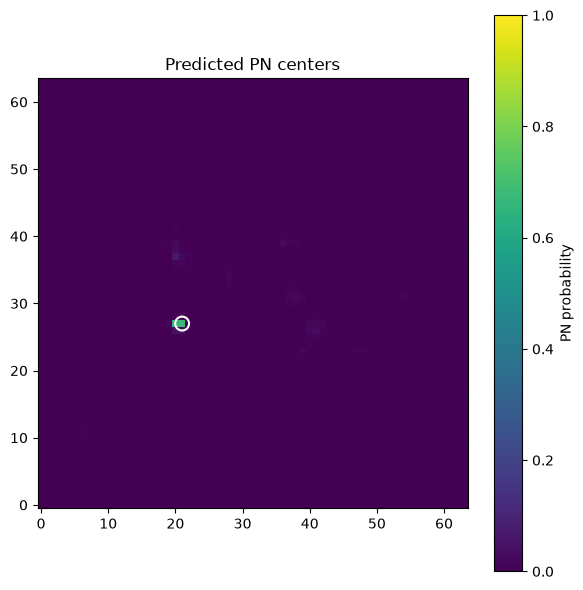

In [18]:
model=keras.models.load_model(
    MODEL_PATH,
    custom_objects={"center_focal_loss":center_focal_loss}
)

test_loss=model.evaluate(test_ds,verbose=1)
print("Best-model test loss:",test_loss)

i=min(50,len(X_test)-1)
pred=model.predict(X_test[i:i+1],verbose=0)[0,:,:,0]
truth=Y_test[i,:,:,0]

plt.figure(figsize=(6,5))
plt.imshow(pred,origin="lower",vmin=0,vmax=1)
plt.colorbar(label="Predicted PN probability")
plt.title("Predicted PN heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,5))
plt.imshow(truth,origin="lower",vmin=0,vmax=1)
plt.colorbar(label="Target")
plt.title("True PN heatmap")
plt.tight_layout()
plt.show()

detections=find_pn_centers(pred,PEAK_THRESHOLD,MIN_DISTANCE)

plt.figure(figsize=(6,6))
plt.imshow(pred,origin="lower",vmin=0,vmax=1)
plt.colorbar(label="PN probability")
if len(detections):
    plt.scatter(detections[:,0],detections[:,1],facecolors="none",edgecolors="white",s=100,linewidths=1.5)
plt.title("Predicted PN centers")
plt.tight_layout()
plt.show()

## Select detection threshold on validation set only

E0000 00:00:1791991902.200900 1985843 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1791991907.955615 1985843 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

threshold  precision  recall  F1
0.10       0.563      0.982   0.715
0.15       0.633      0.981   0.769
0.20       0.678      0.977   0.801
0.25       0.719      0.970   0.826
0.30       0.757      0.961   0.847
0.35       0.784      0.952   0.860
0.40       0.815      0.939   0.872
0.45       0.842      0.910   0.875
0.50       0.866      0.875   0.870
0.55       0.887      0.796   0.839
0.60       0.907      0.704   0.793
0.65       0.933      0.595   0.726
0.70       0.951      0.452   0.613
0.75       0.958      0.297   0.454
0.80       0.983      0.157   0.271
0.85       0.989      0.060   0.114
0.90       1.000      0.018   0.036
Best validation threshold: 0.45000000000000007


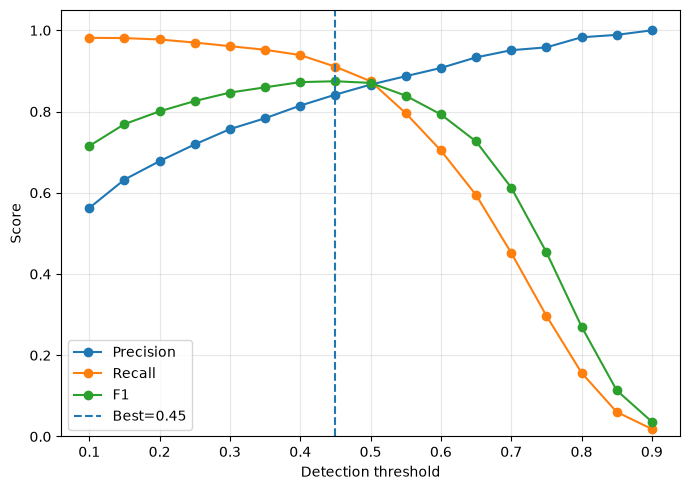

In [19]:
thresholds=np.arange(0.10,0.91,0.05)
results=[]

for threshold in thresholds:
    m=evaluate_detector(
        model,X_val,Y_val,M_val,
        threshold=float(threshold),
        min_distance=MIN_DISTANCE,
        match_tolerance=MATCH_TOLERANCE,
        verbose=0
    )
    results.append([threshold,m["precision"],m["recall"],m["f1"]])

results=np.asarray(results,dtype=np.float64)

print("threshold  precision  recall  F1")
for row in results:
    print(f"{row[0]:.2f}       {row[1]:.3f}      {row[2]:.3f}   {row[3]:.3f}")

best_index=np.argmax(results[:,3])
best_threshold=float(results[best_index,0])
print("Best validation threshold:",best_threshold)

plt.figure(figsize=(7,5))
plt.plot(results[:,0],results[:,1],marker="o",label="Precision")
plt.plot(results[:,0],results[:,2],marker="o",label="Recall")
plt.plot(results[:,0],results[:,3],marker="o",label="F1")
plt.axvline(best_threshold,linestyle="--",label=f"Best={best_threshold:.2f}")
plt.xlabel("Detection threshold")
plt.ylabel("Score")
plt.ylim(0,1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Final held-out test evaluation

In [20]:
final_metrics=evaluate_detector(
    model,X_test,Y_test,M_test,
    threshold=best_threshold,
    min_distance=MIN_DISTANCE,
    match_tolerance=MATCH_TOLERANCE,
    verbose=1
)

print("Final test metrics:")
for key,value in final_metrics.items():
    if key!="localization_errors":
        print(f"{key}: {value}")

print("\nFalse positives by negative type:")
negative_subset_fp_rate(model,X_test,Y_test,types_test,has_injected_pn[test_idx],best_threshold)
print("\nFalse positives by negative type at fixed score 0.45:")
negative_subset_fp_rate(model,X_test,Y_test,types_test,has_injected_pn[test_idx],0.45)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Final test metrics:
TP: 1326
FP: 264
FN: 144
TN: 764
negative_images: 873
negative_images_with_FP: 109
specificity: 0.8751431844215349
false_positive_image_rate: 0.12485681557846506
precision: 0.8339622641509434
recall: 0.9020408163265307
f1: 0.8666666666666666
mean_localization_error: 0.12594269216060638
median_localization_error: 0.0
rmse_localization_error: 0.3548840582370758
std_localization_error: 0.33178475499153137

False positives by negative type:
negative_type     N     image_FP_rate
all_pn_free       807   0.128
compact_nonpn     774   0.133
diffuse_nonpn      19   0.000
background         14   0.000

False positives by negative type at fixed score 0.45:
negative_type     N     image_FP_rate
all_pn_free       807   0.128
compact_nonpn     774   0.133
diffuse_nonpn      19   0.000
background         14   0.000


## Save normalization and experiment configuration

In [21]:
# ============================================================
# Held-out source-score calibration (not pixel-dominated calibration)
# ============================================================
def heldout_detection_calibration(model,X_eval,Y_eval,M_eval,threshold_floor=0.01):
    predictions=model.predict(X_eval,batch_size=BATCH_SIZE,verbose=0)
    scores, outcomes=[] ,[]
    for pred_map,true_map,valid_mask in zip(predictions,Y_eval,M_eval):
        detections=find_pn_centers(pred_map[:,:,0],threshold_floor,MIN_DISTANCE)
        if len(detections):
            px=np.clip(np.rint(detections[:,0]).astype(int),0,valid_mask.shape[1]-1)
            py=np.clip(np.rint(detections[:,1]).astype(int),0,valid_mask.shape[0]-1)
            detections=detections[valid_mask[py,px,0]>0.5]
        true_centers=find_true_centers(true_map[:,:,0])
        matched_true=set()
        for x,y,score in detections:
            outcome=0.0
            if len(true_centers):
                distances=np.hypot(true_centers[:,0]-x,true_centers[:,1]-y)
                for j in np.argsort(distances):
                    if distances[j]>MATCH_TOLERANCE:
                        break
                    if int(j) not in matched_true:
                        matched_true.add(int(j)); outcome=1.0; break
            scores.append(float(score)); outcomes.append(outcome)
    scores=np.asarray(scores); outcomes=np.asarray(outcomes)
    edges=np.linspace(0,1,11)
    rows=[]
    for lo,hi in zip(edges[:-1],edges[1:]):
        use=(scores>=lo)&(scores<(hi if hi<1 else hi+1e-9))
        if use.any():
            rows.append((lo,hi,int(use.sum()),float(scores[use].mean()),float(outcomes[use].mean())))
    brier=float(np.mean((scores-outcomes)**2)) if len(scores) else np.nan
    ece=float(sum(n*abs(conf-acc) for _,_,n,conf,acc in rows)/len(scores)) if len(scores) else np.nan
    print("bin_lo bin_hi N mean_score empirical_precision")
    for row in rows: print(f"{row[0]:.1f} {row[1]:.1f} {row[2]:6d} {row[3]:.3f} {row[4]:.3f}")
    print("Detection-level Brier score:",brier)
    print("10-bin expected calibration error:",ece)
    return rows,brier,ece

calibration_rows,test_brier,test_ece=heldout_detection_calibration(model,X_test,Y_test,M_test)


bin_lo bin_hi N mean_score empirical_precision
0.0 0.1  14269 0.023 0.000
0.1 0.2    477 0.140 0.023
0.2 0.3    222 0.248 0.104
0.3 0.4    176 0.350 0.227
0.4 0.5    219 0.453 0.479
0.5 0.6    314 0.555 0.669
0.6 0.7    432 0.652 0.838
0.7 0.8    477 0.749 0.937
0.8 0.9    229 0.838 0.991
0.9 1.0     19 0.923 0.947
Detection-level Brier score: 0.020544686124939367
10-bin expected calibration error: 0.040554093661653565


In [22]:
np.savez(
    NORM_PATH,
    transform=np.asarray("four_flux_asinh_zscore_plus_error_asinh_zscore"),
    line_names=np.asarray(line_names),
    flux_scale=np.float64(FLUX_SCALE),
    asinh_percentile=np.float64(ASINH_PERCENTILE),
    asinh_scale=np.asarray(asinh_scale,dtype=np.float64),
    flux_channel_means=np.asarray(flux_means,dtype=np.float64),
    flux_channel_stds=np.asarray(flux_stds,dtype=np.float64),
    error_transform=np.asarray("asinh_zscore"),
    error_asinh_percentile=np.float64(ERROR_ASINH_PERCENTILE),
    error_asinh_scale=np.float64(error_asinh_scale),
    error_channel_mean=np.float64(error_mean),
    error_channel_std=np.float64(error_std),
    channel_means=np.asarray(channel_means,dtype=np.float64),
    channel_stds=np.asarray(channel_stds,dtype=np.float64),
    detection_threshold=np.float64(best_threshold)
)

config={
    "architecture":"Residual U-Net",
    "residual_block":"2x Conv3x3-BN with identity/projection shortcut",
    "feature_widths":[32,64,128,256],
    "seed":SEED,
    "data_path":str(DATA_PATH),
    "model_path":str(MODEL_PATH),
    "batch_size":BATCH_SIZE,
    "initial_learning_rate":LEARNING_RATE,
    "weight_decay":WEIGHT_DECAY,
    "clipnorm":CLIPNORM,
    "max_epochs":MAX_EPOCHS,
    "checkpoint_monitor":"val_loss",
    "flux_scale":FLUX_SCALE,
    "asinh_percentile":ASINH_PERCENTILE,
    "error_asinh_percentile":ERROR_ASINH_PERCENTILE,
    "error_asinh_scale":error_asinh_scale,
    "loss_masking":"radius-5 around measured OIII S/N < 10 injected PNe",
    "dropout":0.20,
    "peak_threshold_initial":PEAK_THRESHOLD,
    "best_validation_threshold":best_threshold,
    "min_distance":MIN_DISTANCE,
    "match_tolerance":MATCH_TOLERANCE,
    "line_names":[str(x) for x in line_names],
    "train_size":int(len(train_idx)),
    "val_size":int(len(val_idx)),
    "test_size":int(len(test_idx))
}

with open(CONFIG_PATH,"w") as f:
    json.dump(config,f,indent=2)

print("Saved normalization:",NORM_PATH)
print("Saved config:",CONFIG_PATH)

Saved normalization: PN_ResUNet_normalization_v4.9.1_5channel_snr_gated_cpuinput.npz
Saved config: PN_ResUNet_training_config_v4.9.1_5channel_snr_gated_cpuinput.json


## Reproducibility checksums

In [23]:
def sha256_file(path,chunk_size=1024*1024):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        while True:
            chunk=f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

print("Dataset SHA256:",sha256_file(DATA_PATH))
print("Model SHA256:",sha256_file(MODEL_PATH))
print("Training complete.")

Dataset SHA256: 82e388d0fb71ec114b532265719b92e851b522552ee15762f7aeb81b63ba8d7c
Model SHA256: d26ce5811e4bea9d234d9c1253531dc671c8422673c60cba74a0260f53569b88
Training complete.
